In [1]:
# Cell 1: setup (Kaggle)
import os
PROJ = '/kaggle/working/sarcasm_cascade'   # everything we save goes here
os.makedirs(f'{PROJ}/cache', exist_ok=True)

!nvidia-smi -L
!apt-get -qq install -y ffmpeg > /dev/null 2>&1; ffmpeg -version | head -1
!pip -q install faster-whisper open_clip_torch faiss-cpu google-genai streamlit jiwer gdown

!git clone -q https://github.com/soujanyaporia/MUStARD.git /kaggle/working/MUStARD 2>/dev/null || echo "already cloned"

import json, re, pandas as pd
with open('/kaggle/working/MUStARD/data/sarcasm_data.json') as f:
    raw = json.load(f)

df = pd.DataFrame.from_dict(raw, orient='index')
df.index.name = 'clip_id'
df = df.reset_index()

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df['sarcasm'].value_counts())
print(df['show'].value_counts())
print("Example row:", df.iloc[0].to_dict())
df.to_pickle(f'{PROJ}/labels.pkl')

# The repo README links to the raw videos. Print those links so we download the right file.
readme = open('/kaggle/working/MUStARD/README.md').read()
print("Drive links in README:", set(re.findall(r'https?://drive\.google\.com/[^\s\)\]]+', readme)))

GPU 0: Tesla T4 (UUID: GPU-90009df0-5a4f-d294-da48-037b7fd1f1e8)
GPU 1: Tesla T4 (UUID: GPU-756164c2-b062-7797-1feb-8c22c9d8c106)
ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
Shape: (690, 7)
Columns: ['clip_id', 'utterance', 'speaker', 'context', 'context_speakers', 'show', 'sarcasm']
sarcasm
True     345
False    345
Name: count, dtype: int64
show
FRIENDS           356
BBT               280
GOLDENGIRLS        40
SARCASMOHOLICS     14
Name: count, dtype: int64
Example row: {'clip_id': '1_60', 'utterance': "It's just a privilege to watch your mind at work.", 'speaker': 'SHELDON', 'context': ['I never would have identified the fingerprints of string theory in the aftermath of the Big Bang.', "My apologies. What's your plan?"], 'context_speakers': ['LEONARD', 'SHELDON'], 'show': 'BBT', 'sarcasm': True}
Drive links in README: set()


In [2]:
# Cell 2: download raw videos (link from the MUStARD README, now hosted on Hugging Face)
import os, glob
RAW = '/kaggle/working/raw'
os.makedirs(RAW, exist_ok=True)

if not os.path.exists(f'{RAW}/mmsd_raw_data.zip'):
    !wget -q --show-progress -O {RAW}/mmsd_raw_data.zip https://huggingface.co/datasets/MichiganNLP/MUStARD/resolve/main/mmsd_raw_data.zip
!ls -lh {RAW}/mmsd_raw_data.zip
!unzip -q -o {RAW}/mmsd_raw_data.zip -d {RAW}
!rm {RAW}/mmsd_raw_data.zip   # free disk space after unzipping

# Show what folders we got and how many videos are in each
for d in sorted(glob.glob(f'{RAW}/**/', recursive=True)):
    n = len(glob.glob(f'{d}*.mp4'))
    if n: print(n, "videos in", d)

# Find the utterance folder and check it matches our labels
utt_dirs = [d for d in glob.glob(f'{RAW}/**/', recursive=True) if 'utterance' in d.lower()]
print("Utterance folder candidates:", utt_dirs)
UTT = utt_dirs[0]
ids_on_disk = {os.path.splitext(os.path.basename(p))[0] for p in glob.glob(f'{UTT}*.mp4')}
missing = set(df['clip_id']) - ids_on_disk
print("Labels:", len(df), "| videos found:", len(ids_on_disk), "| labels with no video:", len(missing))
print("Example missing:", list(missing)[:5])

/kaggle/working/raw 100%[===================>]   1.31G  35.0MB/s    in 19s     
-rw-r--r-- 1 root root 1.4G Oct 25 14:47 /kaggle/working/raw/mmsd_raw_data.zip
690 videos in /kaggle/working/raw/context_final/
690 videos in /kaggle/working/raw/utterances_final/
Utterance folder candidates: ['/kaggle/working/raw/utterances_final/', '/kaggle/working/raw/__MACOSX/utterances_final/']
Labels: 690 | videos found: 690 | labels with no video: 0
Example missing: []


In [4]:
# Cell 3: audio extraction + Whisper ASR + WER  (fixed: load wav with scipy, bypass PyAV)
import os, time, subprocess, shutil, re
import numpy as np, pandas as pd, jiwer
from scipy.io import wavfile
from faster_whisper import WhisperModel

shutil.rmtree('/kaggle/working/raw/__MACOSX', ignore_errors=True)
UTT = '/kaggle/working/raw/utterances_final/'
AUD = '/kaggle/working/audio'
os.makedirs(AUD, exist_ok=True)

# 1) extract 16kHz mono wav for every utterance clip (skips files that already exist)
for cid in df['clip_id']:
    out = f'{AUD}/{cid}.wav'
    if not os.path.exists(out):
        subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', f'{UTT}{cid}.mp4',
                        '-ac', '1', '-ar', '16000', out], check=True)
print("wav files:", len(os.listdir(AUD)))

def load_wav(path):
    sr, x = wavfile.read(path)            # int16, 16 kHz mono
    assert sr == 16000
    return x.astype(np.float32) / 32768.0

# 2) transcribe (cached to CSV so we never redo it)
ASR_CSV = f'{PROJ}/cache/asr_whisper_small.csv'
if os.path.exists(ASR_CSV):
    asr = pd.read_csv(ASR_CSV, keep_default_na=False)
    print("Loaded cached ASR")
else:
    model = WhisperModel('small', device='cuda', compute_type='float16')
    rows = []
    for i, cid in enumerate(df['clip_id']):
        t0 = time.perf_counter()
        segs, _ = model.transcribe(load_wav(f'{AUD}/{cid}.wav'), language='en', beam_size=5,
                                   condition_on_previous_text=False)
        text = ' '.join(s.text.strip() for s in segs).strip()
        rows.append({'clip_id': cid, 'asr_text': text, 'asr_sec': time.perf_counter() - t0})
        if i % 100 == 0: print(i, cid, '->', text)
    asr = pd.DataFrame(rows)
    asr.to_csv(ASR_CSV, index=False)

df = df.drop(columns=['asr_text', 'asr_sec'], errors='ignore').merge(asr, on='clip_id')
df.to_pickle(f'{PROJ}/labels.pkl')

# 3) WER vs gold (lowercase, strip punctuation)
def norm(s):
    s = re.sub(r"[^a-z0-9' ]", ' ', str(s).lower())
    return re.sub(r'\s+', ' ', s).strip()

refs = [norm(t) for t in df['utterance']]
hyps = [norm(t) for t in df['asr_text']]
n_empty = sum(h == '' for h in hyps)
hyps = [h if h else 'x' for h in hyps]   # placeholder so empty outputs count as errors, not crashes
print(f"\nCorpus WER (Whisper small vs gold): {jiwer.wer(refs, hyps):.3f}")
print("Empty transcripts:", n_empty)
print(f"ASR time per clip: mean {df['asr_sec'].mean():.3f}s, median {df['asr_sec'].median():.3f}s")
print(df.groupby('show').apply(lambda g: jiwer.wer([norm(t) for t in g['utterance']],
                                                    [norm(t) or 'x' for t in g['asr_text']])).round(3))
print("\nExamples:")
for _, r in df.sample(5, random_state=0).iterrows():
    print("GOLD:", r['utterance'], "\nASR :", r['asr_text'], "\n")

wav files: 690
0 1_60 -> It's just a privilege to watch your mind at work.
100 1_4290 -> I just have a question. Does Bernadette ever talk about me?
200 1_8159 -> And I'm cool with surprises, but nothing on a jumbotron. I don't want to cry on a big screen like that.
300 2_286 -> But sometimes, I'll want you to steal third, and I'll go like this.
400 2_240 -> I'm not mad at us anymore. No.
500 2_481 -> Careful.
600 2_291 -> Would you please excuse me for a moment?

Corpus WER (Whisper small vs gold): 0.169
Empty transcripts: 0
ASR time per clip: mean 0.245s, median 0.191s
show
BBT               0.106
FRIENDS           0.238
GOLDENGIRLS       0.219
SARCASMOHOLICS    0.530
dtype: float64

Examples:
GOLD: That woman looks exactly like the pictures of Princess Panchali in the book. How often does one see a beloved fictional character come to life? 
ASR : That woman looks exactly like the pictures of Princess Pinchale in the book. How often does one see a beloved fictional character come to 

/tmp/ipykernel_49/1946733898.py:58: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(df.groupby('show').apply(lambda g: jiwer.wer([norm(t) for t in g['utterance']],


In [5]:
# Cell 4: context ASR + RoBERTa text features (cached to .npy)
import os, glob, time, subprocess, re
import numpy as np, pandas as pd, torch, jiwer
from transformers import AutoTokenizer, AutoModel

CTX = '/kaggle/working/raw/context_final/'
C = f'{PROJ}/cache'
np.save(f'{C}/clip_ids.npy', df['clip_id'].values)   # row order used by every .npy file

def load_audio_ffmpeg(path):
    out = subprocess.run(['ffmpeg', '-loglevel', 'error', '-i', path, '-f', 's16le',
                          '-ac', '1', '-ar', '16000', '-'], capture_output=True, check=True).stdout
    return np.frombuffer(out, np.int16).astype(np.float32) / 32768.0

# 1) transcribe context clips (cached)
CTX_CSV = f'{C}/asr_context_whisper_small.csv'
if os.path.exists(CTX_CSV):
    ctx = pd.read_csv(CTX_CSV, keep_default_na=False)
    print("Loaded cached context ASR")
else:
    from faster_whisper import WhisperModel
    wm = WhisperModel('small', device='cuda', compute_type='float16')
    rows = []
    for i, cid in enumerate(df['clip_id']):
        files = glob.glob(f'{CTX}{cid}_c.mp4') or glob.glob(f'{CTX}{cid}*.mp4')
        t0 = time.perf_counter()
        segs, _ = wm.transcribe(load_audio_ffmpeg(files[0]), language='en', beam_size=5,
                                condition_on_previous_text=False)
        text = ' '.join(s.text.strip() for s in segs).strip()
        rows.append({'clip_id': cid, 'ctx_asr_text': text, 'ctx_asr_sec': time.perf_counter() - t0})
        if i % 100 == 0: print(i, cid, '->', text[:100])
    ctx = pd.DataFrame(rows)
    ctx.to_csv(CTX_CSV, index=False)
    del wm; torch.cuda.empty_cache()

df = df.drop(columns=['ctx_asr_text', 'ctx_asr_sec'], errors='ignore').merge(ctx, on='clip_id')
df.to_pickle(f'{PROJ}/labels.pkl')

def norm(s):
    s = re.sub(r"[^a-z0-9' ]", ' ', str(s).lower())
    return re.sub(r'\s+', ' ', s).strip()
gold_ctx = [norm(' '.join(c)) for c in df['context']]
hyp_ctx = [norm(t) or 'x' for t in df['ctx_asr_text']]
print(f"Context WER (Whisper small vs gold): {jiwer.wer(gold_ctx, hyp_ctx):.3f}")
print(f"Context ASR time per clip: mean {df['ctx_asr_sec'].mean():.3f}s")

# 2) RoBERTa embeddings: mean-pooled last layer, one clip at a time (timed for cascade cost)
TXT_NPY = f'{C}/text_roberta.npy'
if os.path.exists(TXT_NPY):
    X_text = np.load(TXT_NPY); text_sec = np.load(f'{C}/text_sec.npy')
    print("Loaded cached text features")
else:
    dev = 'cuda:0'
    tok = AutoTokenizer.from_pretrained('roberta-base')
    rob = AutoModel.from_pretrained('roberta-base').to(dev).eval()

    @torch.no_grad()
    def embed(text):
        enc = tok(text or ' ', return_tensors='pt', truncation=True, max_length=256).to(dev)
        h = rob(**enc).last_hidden_state
        m = enc['attention_mask'].unsqueeze(-1).float()
        return ((h * m).sum(1) / m.sum(1)).squeeze(0).cpu().numpy()

    embed("warm up the GPU"); torch.cuda.synchronize()
    feats, secs = [], []
    for utt, c in zip(df['asr_text'], df['ctx_asr_text']):
        t0 = time.perf_counter()
        v = np.concatenate([embed(utt), embed(c)])
        torch.cuda.synchronize()
        secs.append(time.perf_counter() - t0); feats.append(v)
    X_text, text_sec = np.stack(feats), np.array(secs)
    np.save(TXT_NPY, X_text); np.save(f'{C}/text_sec.npy', text_sec)
    del rob; torch.cuda.empty_cache()

print("X_text shape:", X_text.shape)
print(f"RoBERTa time per clip: mean {text_sec.mean()*1000:.1f} ms")
print(f"Stage-1 text cost per clip (utt ASR + ctx ASR + RoBERTa): "
      f"{(df['asr_sec'] + df['ctx_asr_sec']).mean() + text_sec.mean():.3f}s")

0 1_60 -> At the first little hitch I never would have been able to identify the fingerprints of string theory
100 1_4290 -> Would you have opened the door if you knew it was me? Not since I found out the teddy bear you gave 
200 1_8159 -> If someday you decide you want to get married, you have to propose to me. Really? Yes. It's all on y
300 2_286 -> And sometimes I may be away longer, like this. But I'll still always come back. Like this.
400 2_240 -> We had the best time. Yay! Oh, so Dear Night, you're not mad at us anymore. No, no, no, you guys are
500 2_481 -> Okay, let's use this brush. Okay. Okay. Okay. Brust off. Yeah, careful. Okay, brust off. Yeah.
600 2_291 -> I need to talk to you. It's pretty urgent. It's about Monica and Chandler. Oh my god. Um, of course.
Context WER (Whisper small vs gold): 0.236
Context ASR time per clip: mean 0.651s


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


X_text shape: (690, 1536)
RoBERTa time per clip: mean 16.9 ms
Stage-1 text cost per clip (utt ASR + ctx ASR + RoBERTa): 0.913s


In [ ]:
# Cell 5: wav2vec2 audio features (cached to .npy, timed per clip)
import os, time
import numpy as np, torch
from scipy.io import wavfile
from transformers import AutoFeatureExtractor, Wav2Vec2Model

C = f'{PROJ}/cache'
AUD = '/kaggle/working/audio'
dev = 'cuda:0'

def load_wav(path):
    sr, x = wavfile.read(path)
    return x.astype(np.float32) / 32768.0

AUD_NPY = f'{C}/audio_wav2vec2.npy'
if os.path.exists(AUD_NPY):
    X_audio = np.load(AUD_NPY); audio_sec = np.load(f'{C}/audio_sec.npy')
    print("Loaded cached audio features")
else:
    fe = AutoFeatureExtractor.from_pretrained('facebook/wav2vec2-base')
    w2v = Wav2Vec2Model.from_pretrained('facebook/wav2vec2-base').to(dev).eval()

    @torch.no_grad()
    def audio_embed(path):
        x = load_wav(path)
        inp = fe(x, sampling_rate=16000, return_tensors='pt').input_values.to(dev)
        return w2v(inp).last_hidden_state.mean(1).squeeze(0).cpu().numpy()

    audio_embed(f"{AUD}/{df['clip_id'][0]}.wav"); torch.cuda.synchronize()   # warm-up
    feats, secs = [], []
    for i, cid in enumerate(df['clip_id']):
        t0 = time.perf_counter()
        feats.append(audio_embed(f'{AUD}/{cid}.wav'))
        torch.cuda.synchronize(); secs.append(time.perf_counter() - t0)
        if i % 200 == 0: print("audio", i)
    X_audio, audio_sec = np.stack(feats), np.array(secs)
    np.save(AUD_NPY, X_audio); np.save(f'{C}/audio_sec.npy', audio_sec)
    del w2v; torch.cuda.empty_cache()

print("X_audio:", X_audio.shape)
print(f"wav2vec2 time per clip: mean {audio_sec.mean()*1000:.1f} ms")

In [7]:
# Cell 5b: CLIP video features (fixed: frame-read fallback + correct quickgelu model)
import os, time
import numpy as np, torch, cv2, open_clip
from PIL import Image

C = f'{PROJ}/cache'
UTT = '/kaggle/working/raw/utterances_final/'
dev = 'cuda:0'
X_audio = np.load(f'{C}/audio_wav2vec2.npy'); audio_sec = np.load(f'{C}/audio_sec.npy')

clip_model, _, preprocess = open_clip.create_model_and_transforms('ViT-B-32-quickgelu', pretrained='openai')
clip_model = clip_model.to(dev).eval()
n_fallback = 0

def three_frames(path):
    global n_fallback
    cap = cv2.VideoCapture(path)
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    frames = []
    for frac in (0.25, 0.5, 0.75):
        cap.set(cv2.CAP_PROP_POS_FRAMES, max(0, int(n * frac)))
        ok, fr = cap.read()
        if ok: frames.append(fr)
    cap.release()
    if len(frames) < 3:                       # seeking failed -> read every frame, then pick 3
        n_fallback += 1
        cap = cv2.VideoCapture(path); allf = []
        while True:
            ok, fr = cap.read()
            if not ok: break
            allf.append(fr)
        cap.release()
        frames = [allf[int(len(allf) * f)] for f in (0.25, 0.5, 0.75)] if allf else []
    return [Image.fromarray(cv2.cvtColor(f, cv2.COLOR_BGR2RGB)) for f in frames]

@torch.no_grad()
def video_embed(path):
    frames = three_frames(path)
    if not frames: return None
    batch = torch.stack([preprocess(f) for f in frames]).to(dev)
    e = clip_model.encode_image(batch)
    e = e / e.norm(dim=-1, keepdim=True)
    return e.mean(0).cpu().numpy()

video_embed(f"{UTT}{df['clip_id'][0]}.mp4"); torch.cuda.synchronize(); n_fallback = 0   # warm-up
feats, secs, bad = [], [], []
for i, cid in enumerate(df['clip_id']):
    t0 = time.perf_counter()
    v = video_embed(f'{UTT}{cid}.mp4')
    torch.cuda.synchronize(); secs.append(time.perf_counter() - t0)
    if v is None: bad.append(cid); v = np.zeros(512, np.float32)
    feats.append(v)
    if i % 200 == 0: print("video", i)

X_video, video_sec = np.stack(feats), np.array(secs)
np.save(f'{C}/video_clip.npy', X_video); np.save(f'{C}/video_sec.npy', video_sec)
del clip_model; torch.cuda.empty_cache()

print("Clips needing fallback frame read:", n_fallback, "| unreadable clips:", bad)
print("X_audio:", X_audio.shape, "| X_video:", X_video.shape)
print(f"wav2vec2 time per clip: mean {audio_sec.mean()*1000:.1f} ms")
print(f"CLIP (3 frames + decode) time per clip: mean {video_sec.mean()*1000:.1f} ms")
stage1 = (df['asr_sec'] + df['ctx_asr_sec']).mean() + np.load(f'{C}/text_sec.npy').mean()
print(f"Stage-1 cost: {stage1:.3f}s | Stage-2 extra (audio+video): {audio_sec.mean()+video_sec.mean():.3f}s")
!ls -lh {C}

video 0
video 200
video 400
video 600
Clips needing fallback frame read: 44 | unreadable clips: []
X_audio: (690, 768) | X_video: (690, 512)
wav2vec2 time per clip: mean 33.8 ms
CLIP (3 frames + decode) time per clip: mean 242.7 ms
Stage-1 cost: 0.913s | Stage-2 extra (audio+video): 0.277s
total 7.7M
-rw-r--r-- 1 root root 134K Oct 25 15:17 asr_context_whisper_small.csv
-rw-r--r-- 1 root root  64K Oct 25 15:02 asr_whisper_small.csv
-rw-r--r-- 1 root root 5.6K Oct 25 15:19 audio_sec.npy
-rw-r--r-- 1 root root 2.1M Oct 25 15:19 audio_wav2vec2.npy
-rw-r--r-- 1 root root 6.0K Oct 25 15:09 clip_ids.npy
-rw-r--r-- 1 root root 4.1M Oct 25 15:17 text_roberta.npy
-rw-r--r-- 1 root root 5.6K Oct 25 15:17 text_sec.npy
-rw-r--r-- 1 root root 1.4M Oct 25 15:54 video_clip.npy
-rw-r--r-- 1 root root 5.6K Oct 25 15:54 video_sec.npy


In [ ]:
# Cell 6: 5-fold stratified CV, logistic regression, weighted F1
import numpy as np, pandas as pd, time
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, accuracy_score

C = f'{PROJ}/cache'
X_text  = np.load(f'{C}/text_roberta.npy')
X_audio = np.load(f'{C}/audio_wav2vec2.npy')
X_video = np.load(f'{C}/video_clip.npy')
y = df['sarcasm'].astype(int).values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
folds = np.zeros(len(y), int)
for k, (_, te) in enumerate(skf.split(X_text, y)): folds[te] = k
np.save(f'{C}/folds.npy', folds)                  # same split reused everywhere later

setups = {
    'Text':               [X_text],
    'Text + Audio':       [X_text, X_audio],
    'Text + Video':       [X_text, X_video],
    'Text + Audio + Video': [X_text, X_audio, X_video],
}

rows, oof = [], {}
for name, parts in setups.items():
    X = np.hstack(parts)
    p = np.zeros(len(y)); fold_f1 = []; t0 = time.perf_counter()
    for k in range(5):
        tr, te = folds != k, folds == k
        clf = make_pipeline(StandardScaler(),
                            LogisticRegressionCV(Cs=[1e-4, 1e-3, 1e-2, 1e-1, 1], cv=5,
                                                 scoring='f1_weighted', max_iter=5000))
        clf.fit(X[tr], y[tr])
        p[te] = clf.predict_proba(X[te])[:, 1]
        fold_f1.append(f1_score(y[te], (p[te] >= 0.5).astype(int), average='weighted'))
    oof[name] = p
    pred = (p >= 0.5).astype(int)
    rows.append({'Model': name, 'Dims': X.shape[1],
                 'Weighted F1 (mean±std over folds)': f"{100*np.mean(fold_f1):.1f} ± {100*np.std(fold_f1):.1f}",
                 'Pooled F1': round(100*f1_score(y, pred, average='weighted'), 1),
                 'Accuracy': round(100*accuracy_score(y, pred), 1),
                 'Train time (s)': round(time.perf_counter() - t0, 1)})
    print("done:", name)

np.savez(f'{C}/oof_probs.npz', **{k.replace(' + ', '_').replace(' ', ''): v for k, v in oof.items()})
res = pd.DataFrame(rows)
res['Paper baseline (SVM, gold text, speaker-dep.)'] = ['64.6', '—', '71.6', '—']
res.to_csv(f'{PROJ}/results_table.csv', index=False)
pd.set_option('display.width', 200)
print(res.to_string(index=False))

**Stage 3 note:** Gemini Flash (3.5 / 3.6 / 3.7) was tried first for Stage 3 but hit free-tier `503 UNAVAILABLE` and `429` quota limits before enough clips finished, so Stage 3 uses a local **Qwen2.5-3B-Instruct** instead (Cells 8–8b). Cells 5, 6, 7a and 8 were restored after a cleanup and have no saved output; their results are in the README.

In [ ]:
# Cell 7a: FAISS retrieval (per fold) + RAG prompt + the 120 least-certain clips
import json, time, re, os
import numpy as np, faiss

C = f'{PROJ}/cache'
UTT = '/kaggle/working/raw/utterances_final/'

# data for retrieval
X_text = np.load(f'{C}/text_roberta.npy').astype('float32')
Xn = X_text / np.linalg.norm(X_text, axis=1, keepdims=True)
folds = np.load(f'{C}/folds.npy')
y = df['sarcasm'].astype(int).values
oof = np.load(f'{C}/oof_probs.npz')
p_full = oof['Text_Audio_Video']

# one FAISS index per fold, built only from the other 4 folds
indexes = {}
for k in range(5):
    tr_idx = np.where(folds != k)[0]
    idx = faiss.IndexFlatIP(Xn.shape[1]); idx.add(Xn[tr_idx])
    indexes[k] = (idx, tr_idx)

def retrieve(i, k=5):
    idx, tr_idx = indexes[folds[i]]
    _, nn = idx.search(Xn[i:i+1], k)
    return tr_idx[nn[0]]

def short(s, n=300): s = str(s); return s if len(s) <= n else s[:n] + '…'

def build_prompt(i):
    ex = []
    for j, r in enumerate(retrieve(i), 1):
        ex.append(f"Example {j}\nContext: {short(df.at[r,'ctx_asr_text'])}\n"
                  f"Utterance: {df.at[r,'asr_text']}\nLabel: {'SARCASTIC' if y[r] else 'NOT SARCASTIC'}")
    return ("You detect sarcasm in TV sitcom dialogue. Transcripts are automatic and may contain errors.\n\n"
            "Here are 5 similar labelled examples:\n\n" + "\n\n".join(ex) +
            "\n\nNow classify the TARGET clip. The attached video is the target utterance "
            "(use the speaker's tone of voice and facial expression too).\n"
            f"Context: {short(df.at[i,'ctx_asr_text'], 600)}\nUtterance: {df.at[i,'asr_text']}\n\n"
            'Reply with JSON only: {"label": "sarcastic" or "not_sarcastic", "confidence": number 0-1, '
            '"main_cue": "words" or "tone" or "face", "explanation": one short sentence}')

# the 120 clips the full model is least sure about
hard = np.argsort(np.abs(p_full - 0.5))[:120]
np.save(f'{C}/gemini_clip_rows.npy', hard)
print("Uncertainty band covered by these 120: |p-0.5| <", round(float(np.abs(p_full[hard] - 0.5).max()), 3))

In [ ]:
# Cell 8: Stage 3 = local Qwen2.5-3B-Instruct + FAISS RAG (text-only) — load model
import os, json, re, time
import numpy as np, pandas as pd, torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from sklearn.metrics import f1_score, accuracy_score

LLM_ID, DEV3, N = 'Qwen/Qwen2.5-3B-Instruct', 'cuda:1', 120
OUT = f'{C}/qwen_rag.jsonl'

tok3 = AutoTokenizer.from_pretrained(LLM_ID)
llm = AutoModelForCausalLM.from_pretrained(LLM_ID, dtype=torch.float16).to(DEV3).eval()

def prompt_text(i):
    return build_prompt(i).replace(
        "The attached video is the target utterance "
        "(use the speaker's tone of voice and facial expression too).",
        "No video is available; judge from the text.")

In [19]:
# Cell 8b: fixed Qwen RAG loop (model already loaded in Cell 8)
@torch.no_grad()
def qwen_rag(i):
    msgs = [{"role": "system", "content": "You are a careful annotator. Answer with JSON only."},
            {"role": "user", "content": prompt_text(i)}]
    enc = tok3.apply_chat_template(msgs, add_generation_prompt=True, return_tensors='pt',
                                   return_dict=True).to(DEV3)
    n_in = enc['input_ids'].shape[1]
    t0 = time.perf_counter()
    gen = llm.generate(**enc, max_new_tokens=120, do_sample=False, pad_token_id=tok3.eos_token_id)
    torch.cuda.synchronize(DEV3); sec = time.perf_counter() - t0
    text = tok3.decode(gen[0, n_in:], skip_special_tokens=True)
    m = re.search(r'\{.*\}', text, re.S)
    try:
        out = json.loads(m.group(0))
    except Exception:
        out = {'label': 'sarcastic' if re.search(r'\bsarcastic\b', text.lower()) and 'not_sarcastic' not in text.lower()
               else 'not_sarcastic', 'confidence': None, 'main_cue': 'words', 'explanation': text[:200], 'parse_fail': True}
    return {'i': int(i), 'clip_id': df.at[i, 'clip_id'], 'model': LLM_ID, 'sec': sec,
            'in_tokens': int(n_in), 'out_tokens': int(gen.shape[1] - n_in), **out}

qwen_rag(hard[0])   # warm-up (not saved)
done = {json.loads(l)['i'] for l in open(OUT)} if os.path.exists(OUT) else set()
print(f"Already done: {len(done)} / {N}")
for n, i in enumerate(hard[:N]):
    if int(i) in done: continue
    rec = qwen_rag(i)
    with open(OUT, 'a') as f: f.write(json.dumps(rec) + '\n')
    if n % 20 == 0: print(f"{n}: {rec['clip_id']} {rec['label']} ({rec.get('main_cue')}) {rec['sec']:.2f}s")

# ---- results ----
G = pd.DataFrame([json.loads(l) for l in open(OUT)]).drop_duplicates('i')
gi = G['i'].values
g_pred = (G['label'].astype(str).str.lower().str.strip() == 'sarcastic').astype(int).values
f_pred = (p_full[gi] >= 0.5).astype(int)
pf = int(G['parse_fail'].fillna(False).sum()) if 'parse_fail' in G else 0
print(f"\nQwen calls: {len(G)} | JSON parse failures: {pf}")
print(f"On these {len(G)} hard clips:")
print(f"  Qwen RAG     weighted F1 {100*f1_score(y[gi], g_pred, average='weighted'):.1f} | acc {100*accuracy_score(y[gi], g_pred):.1f}")
print(f"  Full fusion  weighted F1 {100*f1_score(y[gi], f_pred, average='weighted'):.1f} | acc {100*accuracy_score(y[gi], f_pred):.1f}")
print(f"  Predicted sarcastic rate: {g_pred.mean():.2f} (true rate {y[gi].mean():.2f})")
print(f"Qwen latency per clip: mean {G['sec'].mean():.2f}s, median {G['sec'].median():.2f}s")
print(f"Tokens per clip: in {G['in_tokens'].mean():.0f}, out {G['out_tokens'].mean():.0f}")
print("Main cue counts:", G['main_cue'].value_counts().to_dict())
print("Example:", G.iloc[0][['clip_id', 'label', 'confidence', 'main_cue', 'explanation']].to_dict())

Already done: 0 / 120
0: 1_7395 sarcastic (tone) 3.48s
20: 1_10190 sarcastic (tone) 3.36s
40: 2_187 sarcastic (tone) 2.99s
60: 1_3599 sarcastic (tone) 3.27s
80: 1_4603 sarcastic (tone) 3.64s
100: 1_12275 sarcastic (tone) 3.25s

Qwen calls: 120 | JSON parse failures: 0
On these 120 hard clips:
  Qwen RAG     weighted F1 35.8 | acc 45.8
  Full fusion  weighted F1 62.5 | acc 62.5
  Predicted sarcastic rate: 0.90 (true rate 0.47)
Qwen latency per clip: mean 2.93s, median 2.89s
Tokens per clip: in 678, out 53
Main cue counts: {'tone': 112, 'words': 8}
Example: {'clip_id': '1_7395', 'label': 'sarcastic', 'confidence': 0.9, 'main_cue': 'tone', 'explanation': "The utterance implies irony by suggesting something as simple as 'big, sad eyes' could lead to sleeping with someone, which is contrary to the context of the conversation."}


Text only        F1 65.8 | cost 0.913s/clip
Full fusion      F1 76.2 | cost 1.190s/clip

Cascade [saver] (thresholds picked on 4 folds, tested on 5th)
  thresholds per fold (fold, t1, t2): [(0, 0.175, 0.0), (1, 0.125, 0.0), (2, 0.15, 0.0), (3, 0.175, 0.0), (4, 0.175, 0.0)]
  F1 74.5 | cost 1.110s/clip -> keeps 97.7% of full-fusion F1 at 93.3% of its cost
  clips reaching Stage 2: 70.1% | Stage 3: 0.0%
  McNemar vs full fusion: [[both right, only cascade right], [only full right, both wrong]] = [[506, 8], [20, 156]], p = 0.036

Cascade [best] (thresholds picked on 4 folds, tested on 5th)
  thresholds per fold (fold, t1, t2): [(0, 0.3, 0.02), (1, 0.3, 0.02), (2, 0.3, 0.02), (3, 0.3, 0.02), (4, 0.275, 0.02)]
  F1 76.6 | cost 1.325s/clip -> keeps 100.5% of full-fusion F1 at 111.4% of its cost
  clips reaching Stage 2: 94.5% | Stage 3: 5.2%
  McNemar vs full fusion: [[both right, only cascade right], [only full right, both wrong]] = [[516, 13], [10, 151]], p = 0.678

Cost per clip: Stage-1 

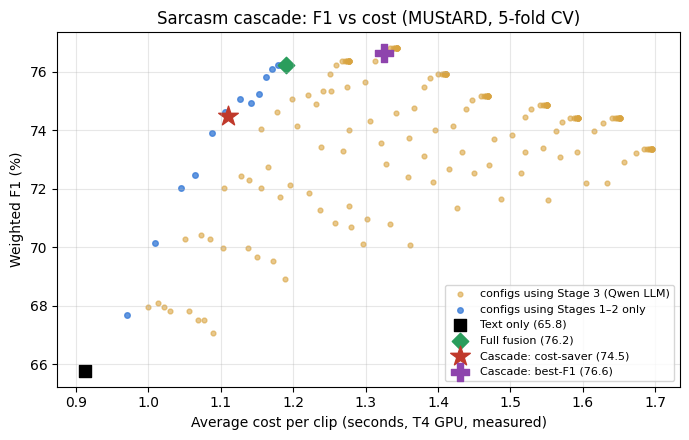


ALL CHECKS PASSED


In [20]:
# Cell 9: 3-stage cascade — sweep, F1 vs cost plot, nested threshold choice, McNemar (self-contained, with checks)
import os, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import f1_score
from statsmodels.stats.contingency_tables import mcnemar

PROJ = '/kaggle/working/sarcasm_cascade'; C = f'{PROJ}/cache'
df = pd.read_pickle(f'{PROJ}/labels.pkl')
y = df['sarcasm'].astype(int).values
oof = np.load(f'{C}/oof_probs.npz'); p1, p2 = oof['Text'], oof['Text_Audio_Video']
folds = np.load(f'{C}/folds.npy')
hard = np.load(f'{C}/gemini_clip_rows.npy')                                    # the 120 least-certain clips (Cell 7a)
s1 = (df['asr_sec'] + df['ctx_asr_sec']).values + np.load(f'{C}/text_sec.npy')  # Stage-1 cost per clip (s)
s2 = np.load(f'{C}/audio_sec.npy') + np.load(f'{C}/video_sec.npy')              # Stage-2 extra cost (s)
Q = pd.DataFrame([json.loads(l) for l in open(f'{C}/qwen_rag.jsonl')]).drop_duplicates('i')
qi = Q['i'].astype(int).values
s3 = np.zeros(len(y)); s3[qi] = Q['sec'].astype(float).values                   # Stage-3 extra cost (s)
q_pred = np.full(len(y), -1); q_pred[qi] = (Q['label'].astype(str).str.lower().str.strip() == 'sarcastic').astype(int).values
u1, u2 = np.abs(p1 - .5), np.abs(p2 - .5)
has_llm = q_pred >= 0
band3_max = u2[has_llm].max()

# ---- input checks ----
n = len(y)
assert n == 690 and len(p1) == len(p2) == len(folds) == len(s1) == len(s2) == n, "length mismatch"
assert not np.isnan(np.r_[p1, p2, s1, s2]).any(), "NaN in probabilities or costs"
assert set(np.unique(folds)) == {0, 1, 2, 3, 4}, "folds must be 0..4"
assert set(qi) <= set(hard.tolist()), "LLM answered a clip outside the hard set"
assert (s3[has_llm] > 0).all(), "missing LLM timing"
assert not (u2[~has_llm] < band3_max).any(), "a clip inside the Stage-3 band has no LLM answer"

def run(t1, t2, idx):
    esc2 = u1[idx] < t1
    esc3 = esc2 & (u2[idx] < t2)
    assert (q_pred[idx][esc3] >= 0).all(), "escalated to Stage 3 without an LLM answer"
    pred = (p1[idx] >= .5).astype(int)
    pred[esc2] = (p2[idx][esc2] >= .5).astype(int)
    pred[esc3] = q_pred[idx][esc3]
    cost = s1[idx] + esc2 * s2[idx] + esc3 * s3[idx]
    return pred, cost, esc2, esc3

T1 = list(np.round(np.arange(0, 0.501, 0.025), 3)) + [0.51]   # 0.51 = every clip goes to Stage 2
T2 = [0.0] + list(np.linspace(0.01, band3_max, 8))             # 0 = never use Stage 3
ALL = np.arange(n)
f1w = lambda yt, yp: f1_score(yt, yp, average='weighted')
text_pred, full_pred = (p1 >= .5).astype(int), (p2 >= .5).astype(int)
F1_text, F1_full = 100 * f1w(y, text_pred), 100 * f1w(y, full_pred)
cost_text, cost_full = s1.mean(), (s1 + s2).mean()

# ---- corner-case checks: the cascade must reduce to the single models ----
pr, co, e2, e3 = run(0.0, 0.0, ALL)
assert (pr == text_pred).all() and np.allclose(co, s1) and e2.sum() == 0, "t1=0 must equal text-only"
pr, co, e2, e3 = run(0.51, 0.0, ALL)
assert (pr == full_pred).all() and np.allclose(co, s1 + s2) and e2.all() and e3.sum() == 0, "t1=0.51,t2=0 must equal full fusion"

# ---- 1) full sweep on all clips (for the plot) ----
rows = []
for t1 in T1:
    for t2 in T2:
        pr, co, e2, e3 = run(t1, t2, ALL)
        rows.append({'t1': t1, 't2': round(float(t2), 3), 'F1': 100 * f1w(y, pr), 'cost_s': co.mean(),
                     'pct_stage2': 100 * e2.mean(), 'pct_stage3': 100 * e3.mean()})
sweep = pd.DataFrame(rows); sweep.to_csv(f'{PROJ}/cascade_sweep.csv', index=False)
assert len(sweep) == len(T1) * len(T2)
assert (sweep.pct_stage3 <= sweep.pct_stage2 + 1e-9).all() and sweep.pct_stage2.between(0, 100).all()
assert (sweep.cost_s >= cost_text - 1e-9).all()
for t2, g in sweep.groupby('t2'):
    assert np.all(np.diff(g.sort_values('t1').cost_s.values) >= -1e-12), "cost must not drop as t1 grows"

# ---- 2) honest estimate: choose thresholds on 4 folds, apply to the held-out 5th ----
#   'saver'  = cheapest config keeping >= 98% of full-fusion F1 (never adds Stage 3 unless needed)
#   'best'   = highest-F1 config (free to use Stage 3 if it helps); ties -> cheaper
KEEP = 0.98
def nested(rule):
    pred, cost = np.full(n, -1), np.zeros(n)
    e2a, e3a, chosen = np.zeros(n, bool), np.zeros(n, bool), []
    for k in range(5):
        sel, te = np.where(folds != k)[0], np.where(folds == k)[0]
        target = KEEP * f1w(y[sel], full_pred[sel])
        best = None
        for t1 in T1:
            for t2 in T2:
                pr, co, _, _ = run(t1, t2, sel); f = f1w(y[sel], pr)
                key = (co.mean(), -f) if rule == 'saver' else (-f, co.mean())
                if (rule == 'best' or f >= target) and (best is None or key < best[0]):
                    best = (key, t1, t2)
        assert best is not None, "no config reached the target (impossible: full fusion always does)"
        _, t1, t2 = best; chosen.append((k, float(t1), round(float(t2), 3)))
        pred[te], cost[te], e2a[te], e3a[te] = run(t1, t2, te)
    assert set(np.unique(pred)) <= {0, 1}, "every clip must get a cascade prediction"
    assert (cost >= s1 - 1e-12).all() and (e3a <= e2a).all()
    a, b = (pred == y), (full_pred == y)
    table = [[int(np.sum(a & b)), int(np.sum(a & ~b))], [int(np.sum(~a & b)), int(np.sum(~a & ~b))]]
    assert sum(map(sum, table)) == n
    p = mcnemar(table, exact=True).pvalue
    assert 0 <= p <= 1
    return dict(pred=pred, cost=cost, e2=e2a, e3=e3a, chosen=chosen, F1=100 * f1w(y, pred), table=table, p=p)

R = {'saver': nested('saver'), 'best': nested('best')}

# ---- report ----
print(f"Text only        F1 {F1_text:.1f} | cost {cost_text:.3f}s/clip")
print(f"Full fusion      F1 {F1_full:.1f} | cost {cost_full:.3f}s/clip")
for name, r in R.items():
    print(f"\nCascade [{name}] (thresholds picked on 4 folds, tested on 5th)")
    print(f"  thresholds per fold (fold, t1, t2): {r['chosen']}")
    print(f"  F1 {r['F1']:.1f} | cost {r['cost'].mean():.3f}s/clip"
          f" -> keeps {100*r['F1']/F1_full:.1f}% of full-fusion F1 at {100*r['cost'].mean()/cost_full:.1f}% of its cost")
    print(f"  clips reaching Stage 2: {100*r['e2'].mean():.1f}% | Stage 3: {100*r['e3'].mean():.1f}%")
    print(f"  McNemar vs full fusion: [[both right, only cascade right], [only full right, both wrong]] = {r['table']}, p = {r['p']:.3f}")
print(f"\nCost per clip: Stage-1 {s1.mean():.3f}s (of which Whisper {(df['asr_sec']+df['ctx_asr_sec']).mean():.3f}s) | "
      f"Stage-2 extra {s2.mean():.3f}s | Stage-3 extra {Q['sec'].mean():.3f}s")
best_any = sweep.loc[sweep['F1'].idxmax()]
print("Best F1 anywhere in sweep (optimistic, picked on all data):", {k: round(float(v), 2) for k, v in best_any.items()})
print("Best sweep F1 with Stage 3 used vs not:",
      round(sweep[sweep.pct_stage3 > 0]['F1'].max(), 1), "vs", round(sweep[sweep.pct_stage3 == 0]['F1'].max(), 1))

# ---- 3) plot ----
fig, ax = plt.subplots(figsize=(7, 4.5))
no3, yes3 = sweep[sweep.t2 == 0], sweep[sweep.t2 > 0]
ax.scatter(yes3.cost_s, yes3.F1, s=12, c='#d9a441', alpha=.6, label='configs using Stage 3 (Qwen LLM)')
ax.scatter(no3.cost_s, no3.F1, s=16, c='#3b7dd8', alpha=.8, label='configs using Stages 1–2 only')
ax.scatter([cost_text], [F1_text], marker='s', s=70, c='k', label=f'Text only ({F1_text:.1f})')
ax.scatter([cost_full], [F1_full], marker='D', s=70, c='#2a9d5c', label=f'Full fusion ({F1_full:.1f})')
ax.scatter([R['saver']['cost'].mean()], [R['saver']['F1']], marker='*', s=220, c='#c0392b', label=f"Cascade: cost-saver ({R['saver']['F1']:.1f})")
ax.scatter([R['best']['cost'].mean()], [R['best']['F1']], marker='P', s=150, c='#8e44ad', label=f"Cascade: best-F1 ({R['best']['F1']:.1f})")
ax.set_xlabel('Average cost per clip (seconds, T4 GPU, measured)'); ax.set_ylabel('Weighted F1 (%)')
ax.set_title('Sarcasm cascade: F1 vs cost (MUStARD, 5-fold CV)'); ax.grid(alpha=.3); ax.legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.savefig(f'{PROJ}/cascade_plot.png', dpi=150); plt.show()

rs = R['saver']
pd.DataFrame({'clip_id': df['clip_id'], 'y': y, 'p_text': p1, 'p_full': p2, 'cascade_pred': rs['pred'],
              'stage': np.where(rs['e3'], 3, np.where(rs['e2'], 2, 1)), 'cost_s': rs['cost']}).to_csv(f'{PROJ}/cascade_per_clip.csv', index=False)
json.dump({'t1_saver': [c[1] for c in rs['chosen']], 't2_saver': [c[2] for c in rs['chosen']],
           't1_best': [c[1] for c in R['best']['chosen']], 't2_best': [c[2] for c in R['best']['chosen']]},
          open(f'{PROJ}/cascade_thresholds.json', 'w'))
for f in ['cascade_sweep.csv', 'cascade_plot.png', 'cascade_per_clip.csv', 'cascade_thresholds.json']:
    assert os.path.getsize(f'{PROJ}/{f}') > 0, f"{f} not written"
print("\nALL CHECKS PASSED")